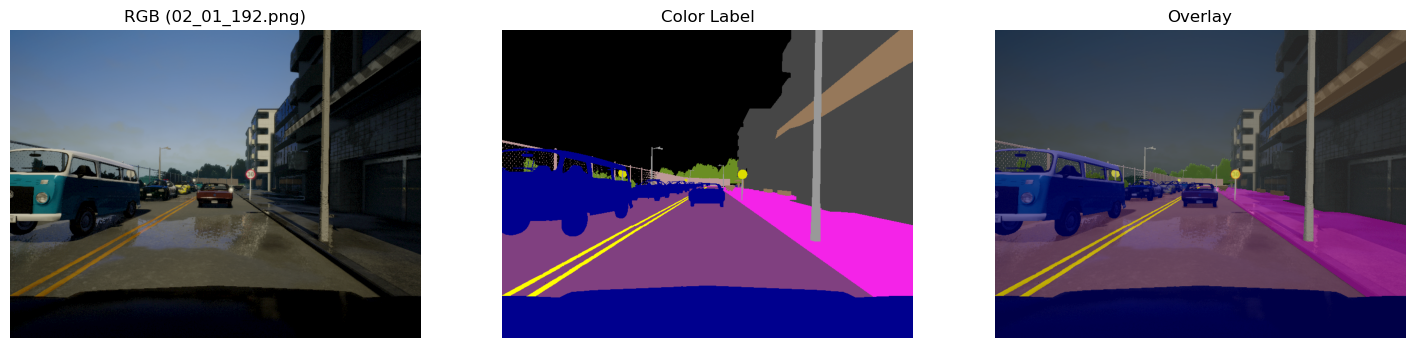

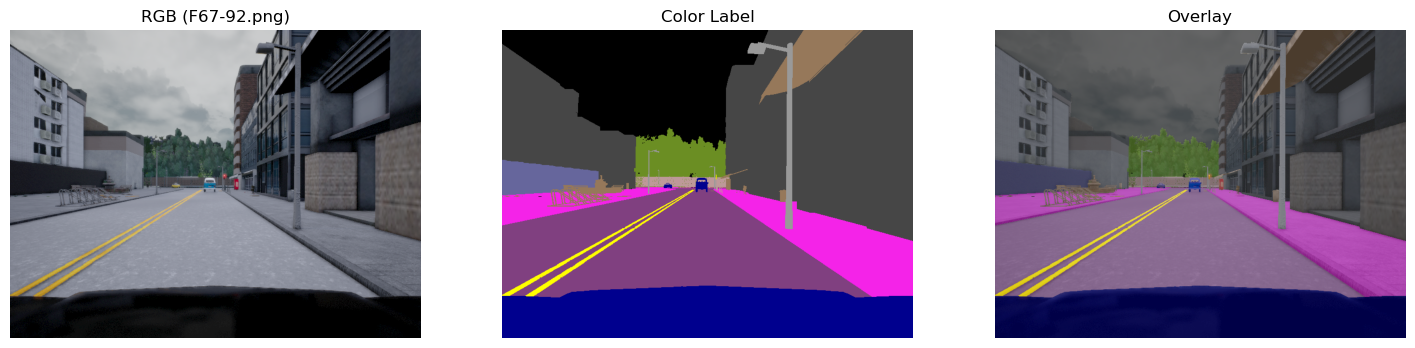

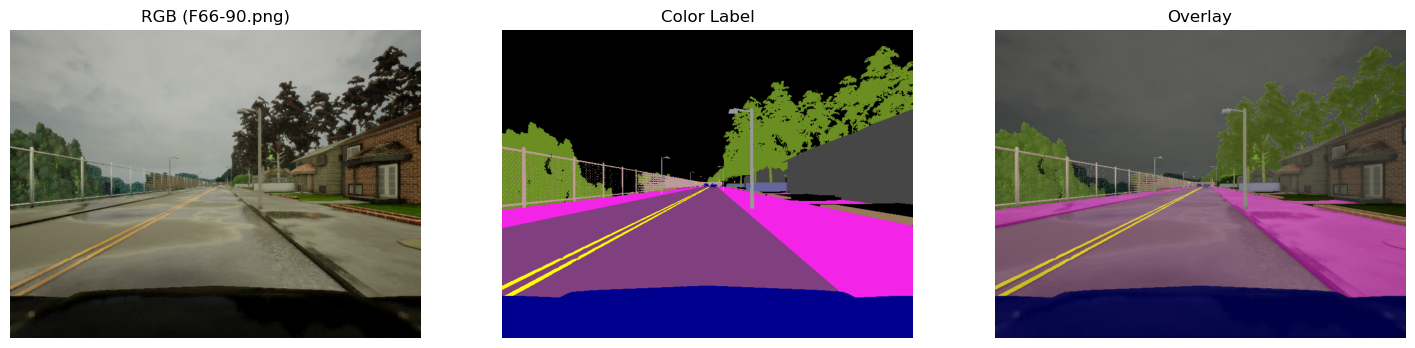

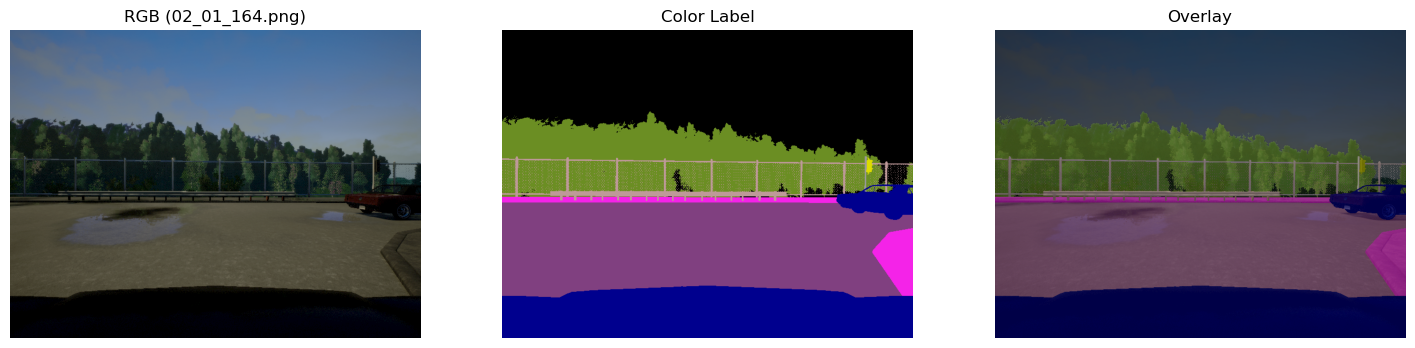

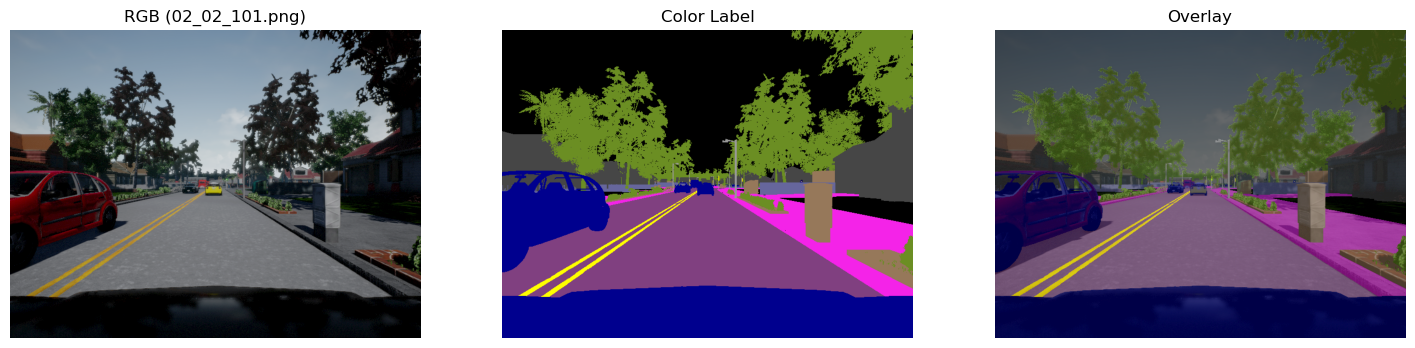

In [13]:
def visualize_random_samples(rgb_dir, label_dir, N=5, alpha=0.5):
    rgb_files = sorted(os.listdir(rgb_dir))
    label_files = sorted(os.listdir(label_dir))

    # 파일명 개수 체크
    if len(rgb_files) != len(label_files):
        print("⚠️ Warning: RGB와 Label 개수가 다릅니다!")
    
    # N개의 랜덤 sample 선택
    indices = random.sample(range(len(rgb_files)), N)

    for idx in indices:
        rgb_path = os.path.join(rgb_dir, rgb_files[idx])
        label_path = os.path.join(label_dir, label_files[idx])

        # Load data
        rgb = np.array(Image.open(rgb_path).convert("RGB"))
        label = load_label(label_path)
        color_label = colorize_mask(label)

        # Overlay 생성
        overlay = (rgb * (1 - alpha) + color_label * alpha).astype(np.uint8)

        # Plot
        plt.figure(figsize=(18,6))

        plt.subplot(1,3,1)
        plt.title(f"RGB ({rgb_files[idx]})")
        plt.imshow(rgb)
        plt.axis("off")

        plt.subplot(1,3,2)
        plt.title("Color Label")
        plt.imshow(color_label)
        plt.axis("off")

        plt.subplot(1,3,3)
        plt.title("Overlay")
        plt.imshow(overlay)
        plt.axis("off")

        plt.show()

visualize_random_samples("Training/RGB", "Training/Label", N=5)


RGB images: 1000
Label images: 1000
Unique image sizes: {(800, 600)}


Class count:   0%|          | 0/1000 [00:00<?, ?it/s]

Class count: 100%|██████████| 1000/1000 [00:14<00:00, 69.02it/s]



Class pixel ratio (%):
Class 0: 28.237%
Class 1: 11.804%
Class 2: 0.781%
Class 3: 1.202%
Class 4: 0.006%
Class 5: 0.490%
Class 6: 0.744%
Class 7: 19.667%
Class 8: 7.973%
Class 9: 11.463%
Class 10: 16.661%
Class 11: 0.893%
Class 12: 0.081%


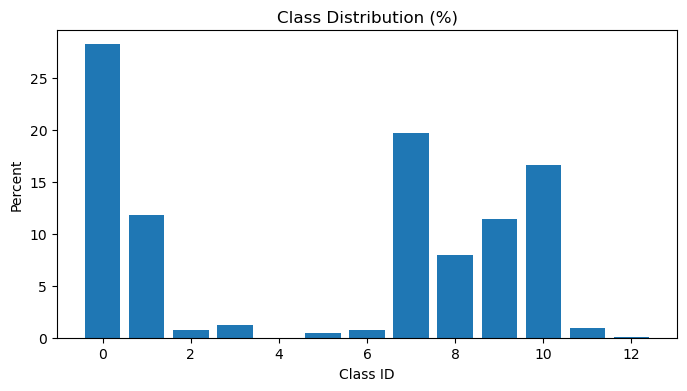

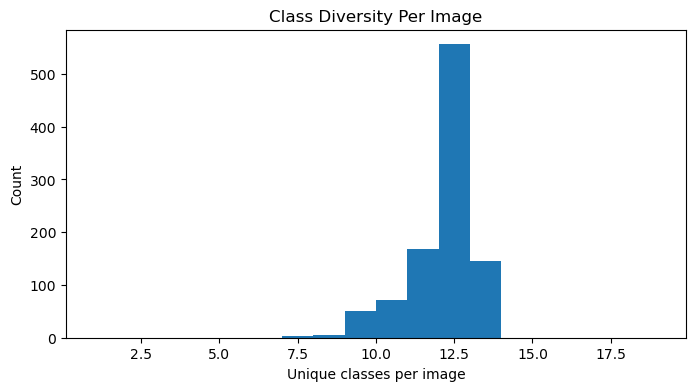

Average classes per image: 11.644

All label values found in dataset: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [9]:
import os
import glob
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# ------------------------------------
# 라벨을 제대로 읽기 위한 함수
# ------------------------------------
def load_label(path):
    raw = np.array(Image.open(path))
    if raw.ndim == 3:
        raw = raw[:, :, 0]  # RGB PNG에서 첫 채널만 사용 (class ID)
    return raw


# ------------------------------------
# EDA 함수
# ------------------------------------
def run_full_eda(rgb_dir, label_dir):
    rgb_paths = sorted(glob.glob(os.path.join(rgb_dir, "*.png")))
    label_paths = sorted(glob.glob(os.path.join(label_dir, "*.png")))

    # --- 1: 파일 수 체크 ---
    print("RGB images:", len(rgb_paths))
    print("Label images:", len(label_paths))

    # --- 2: 해상도 분석 ---
    sizes = []
    for p in rgb_paths[:50]:  # 처음 50장만 체크
        img = Image.open(p)
        sizes.append(img.size)
    print("Unique image sizes:", set(sizes))

    # --- 3: 클래스 비율 분석 ---
    class_counts = {i: 0 for i in range(13)}  # 클래스 ID 0~12

    for lp in tqdm(label_paths, desc="Class count"):
        mask = load_label(lp)
        unique, cnt = np.unique(mask, return_counts=True)
        for u, c in zip(unique, cnt):
            class_counts[u] += c

    total_pixels = sum(class_counts.values())
    class_ratio = {k: v / total_pixels * 100 for k, v in class_counts.items()}

    print("\nClass pixel ratio (%):")
    for k, v in class_ratio.items():
        print(f"Class {k}: {v:.3f}%")

    # 클래스 분포 그래프
    plt.figure(figsize=(8,4))
    plt.bar(class_ratio.keys(), class_ratio.values())
    plt.title("Class Distribution (%)")
    plt.xlabel("Class ID")
    plt.ylabel("Percent")
    plt.show()

    # --- 4: 이미지별 클래스 다양성 ---
    diversity = []
    for lp in label_paths:
        mask = load_label(lp)
        diversity.append(len(np.unique(mask)))

    plt.figure(figsize=(8,4))
    plt.hist(diversity, bins=range(1, 20))
    plt.title("Class Diversity Per Image")
    plt.xlabel("Unique classes per image")
    plt.ylabel("Count")
    plt.show()

    print("Average classes per image:", np.mean(diversity))

    # --- 5: 라벨 값 범위 검사 ---
    all_values = set()
    for lp in label_paths:
        mask = load_label(lp)
        all_values.update(np.unique(mask))

    print("\nAll label values found in dataset:", sorted(list(all_values)))


# ------------------------------------
# 실행
# ------------------------------------
run_full_eda("Training/RGB", "Training/Label")


In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F

NUM_CLASSES = 13  # 라벨 0~12

class BasicSegNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()

        # Encoder: 그냥 일반적인 CNN
        self.enc1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.pool1 = nn.MaxPool2d(2)  # H/2, W/2

        self.enc2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        self.pool2 = nn.MaxPool2d(2)  # H/4, W/4

        self.enc3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.pool3 = nn.MaxPool2d(2)  # H/8, W/8

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )

        # Segmentation head: 1x1 conv로 채널을 클래스 수로 줄임
        self.classifier = nn.Conv2d(256, num_classes, kernel_size=1)

    def forward(self, x):
        H, W = x.shape[2], x.shape[3]  # 원본 해상도 기억

        x = self.enc1(x)
        x = self.pool1(x)

        x = self.enc2(x)
        x = self.pool2(x)

        x = self.enc3(x)
        x = self.pool3(x)

        x = self.bottleneck(x)

        x = self.classifier(x)  # (B, C, H/8, W/8)

        # 원본 크기로 업샘플링
        x = F.interpolate(x, size=(H, W), mode="bilinear", align_corners=False)  # (B, C, H, W)

        return x


In [20]:
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF
from PIL import Image
import numpy as np
import torch
import os

class SegDataset(Dataset):
    def __init__(self, rgb_dir, label_dir, transform=None):
        self.rgb_dir = rgb_dir
        self.label_dir = label_dir
        self.transform = transform

        self.rgb_files = sorted(os.listdir(rgb_dir))
        self.label_files = sorted(os.listdir(label_dir))

        assert len(self.rgb_files) == len(self.label_files), "RGB/Label 개수 불일치"

    def __len__(self):
        return len(self.rgb_files)

    def __getitem__(self, idx):
        # 파일 경로
        rgb_path = os.path.join(self.rgb_dir, self.rgb_files[idx])
        label_path = os.path.join(self.label_dir, self.label_files[idx])

        # RGB 로드
        rgb = Image.open(rgb_path).convert("RGB")
        label_raw = np.array(Image.open(label_path))
        
        # 라벨이 3채널이면 첫 채널 사용
        if label_raw.ndim == 3:
            label = label_raw[:, :, 0]
        else:
            label = label_raw
            
        # To Tensor
        rgb = TF.to_tensor(rgb)                        # → (3,H,W), float32, [0,1]
        label = torch.tensor(label, dtype=torch.long)  # → (H,W), long

        return rgb, label


In [21]:
from torch.utils.data import DataLoader

train_dataset = SegDataset("Training/RGB", "Training/Label")
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)


In [22]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BasicSegNet(num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)  # (B, C, H, W)
        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}]  Loss: {avg_loss:.4f}")


Epoch [1/10]  Loss: 0.6485
Epoch [2/10]  Loss: 0.3766
Epoch [3/10]  Loss: 0.3166
Epoch [4/10]  Loss: 0.2243
Epoch [5/10]  Loss: 0.2173
Epoch [6/10]  Loss: 0.1690
Epoch [7/10]  Loss: 0.1555
Epoch [8/10]  Loss: 0.1705
Epoch [9/10]  Loss: 0.1317
Epoch [10/10]  Loss: 0.1207


In [23]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from PIL import Image
import numpy as np
import torch
import os

NUM_CLASSES = 13  # 0~12

class SegDataset(Dataset):
    def __init__(self, rgb_dir, label_dir):
        self.rgb_dir = rgb_dir
        self.label_dir = label_dir

        self.rgb_files = sorted(os.listdir(rgb_dir))
        self.label_files = sorted(os.listdir(label_dir))

        assert len(self.rgb_files) == len(self.label_files), "RGB/Label 개수 다름!"

    def __len__(self):
        return len(self.rgb_files)

    def __getitem__(self, idx):
        rgb_path = os.path.join(self.rgb_dir, self.rgb_files[idx])
        label_path = os.path.join(self.label_dir, self.label_files[idx])

        rgb = Image.open(rgb_path).convert("RGB")
        label_raw = np.array(Image.open(label_path))

        if label_raw.ndim == 3:
            label = label_raw[:, :, 0]
        else:
            label = label_raw

        rgb = TF.to_tensor(rgb)                        # (3,H,W)
        label = torch.tensor(label, dtype=torch.long)  # (H,W)

        return rgb, label

# 이미 train_dataset은 있다고 가정
val_dataset = SegDataset("Validation/RGB", "Validation/Label")
val_loader  = DataLoader(val_dataset, batch_size=4, shuffle=False)


In [24]:
import numpy as np
import torch

def evaluate_model(model, dataloader, num_classes=NUM_CLASSES, device="cuda"):
    model.eval()
    model.to(device)

    # 전체 pixel 단위 정답/예측 카운트를 위한 변수
    conf_matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    total_correct = 0
    total_pixels = 0

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks  = masks.to(device)  # (B,H,W)

            outputs = model(images)    # (B,C,H,W)
            preds = torch.argmax(outputs, dim=1)  # (B,H,W)

            # Pixel Accuracy
            total_correct += (preds == masks).sum().item()
            total_pixels  += masks.numel()

            # Confusion matrix 업데이트
            # flatten
            preds_flat = preds.view(-1).cpu().numpy()
            masks_flat = masks.view(-1).cpu().numpy()

            for t, p in zip(masks_flat, preds_flat):
                if t < num_classes:  # 혹시 이상한 값 들어간 경우 방어
                    conf_matrix[t, p] += 1

    # Pixel Accuracy
    pixel_acc = total_correct / total_pixels

    # IoU per class
    ious = []
    for cls in range(num_classes):
        tp = conf_matrix[cls, cls]
        fp = conf_matrix[:, cls].sum() - tp
        fn = conf_matrix[cls, :].sum() - tp

        denom = tp + fp + fn
        if denom == 0:
            iou = float("nan")  # 해당 클래스가 아예 없는 경우
        else:
            iou = tp / denom
        ious.append(iou)

    # mIoU (NaN 제외 평균)
    valid_ious = [x for x in ious if not np.isnan(x)]
    miou = np.mean(valid_ious) if len(valid_ious) > 0 else 0.0

    return pixel_acc, ious, miou, conf_matrix


In [25]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pixel_acc, ious, miou, confmat = evaluate_model(model, val_loader, NUM_CLASSES, device)

print(f"Pixel Accuracy: {pixel_acc*100:.2f}%")
print(f"mIoU: {miou*100:.2f}%")

class_names = [
    "None",
    "Buildings",
    "Fences",
    "Other",
    "Pedestrians",
    "Poles",
    "RoadLines",
    "Roads",
    "Sidewalks",
    "Vegetation",
    "Vehicles",
    "Walls",
    "TrafficSigns",
]

for i, iou in enumerate(ious):
    if np.isnan(iou):
        print(f"Class {i:2d} ({class_names[i]:12s}): IoU = N/A (not present)")
    else:
        print(f"Class {i:2d} ({class_names[i]:12s}): IoU = {iou*100:5.2f}%")


Pixel Accuracy: 82.95%
mIoU: 43.85%
Class  0 (None        ): IoU = 87.60%
Class  1 (Buildings   ): IoU = 48.62%
Class  2 (Fences      ): IoU = 13.12%
Class  3 (Other       ): IoU = 15.82%
Class  4 (Pedestrians ): IoU =  0.00%
Class  5 (Poles       ): IoU = 23.26%
Class  6 (RoadLines   ): IoU = 52.31%
Class  7 (Roads       ): IoU = 67.30%
Class  8 (Sidewalks   ): IoU = 50.48%
Class  9 (Vegetation  ): IoU = 61.24%
Class 10 (Vehicles    ): IoU = 90.58%
Class 11 (Walls       ): IoU = 20.72%
Class 12 (TrafficSigns): IoU = 39.03%


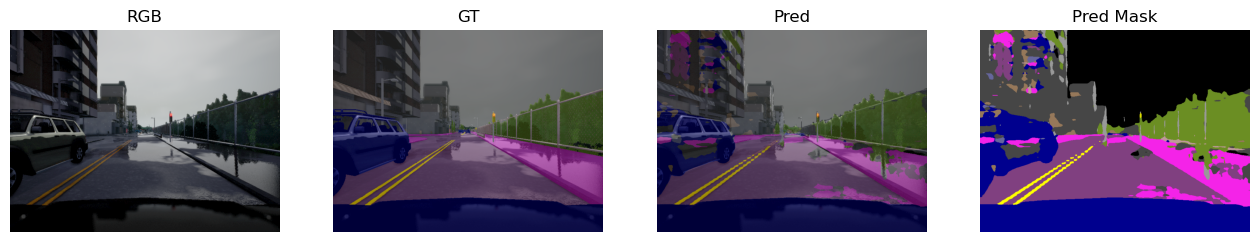

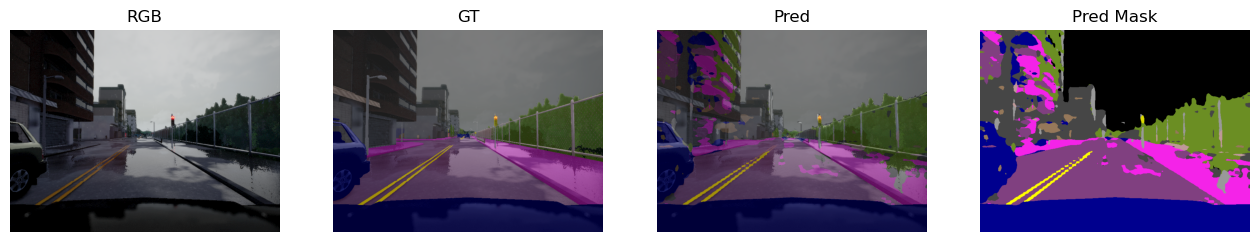

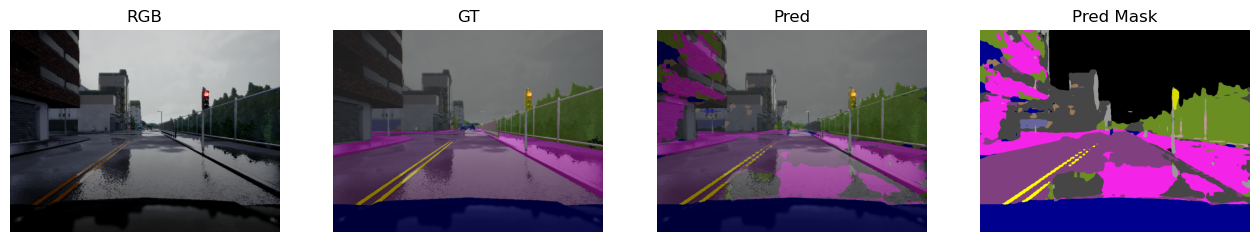

In [26]:
# palette는 이전에 정의한 그대로 사용한다고 가정
palette = np.array([
    [0, 0, 0],          # 0 None
    [70, 70, 70],       # 1 Buildings
    [190, 153, 153],    # 2 Fences
    [150, 120, 90],     # 3 Other
    [220, 20, 60],      # 4 Pedestrians
    [153, 153, 153],    # 5 Poles
    [255, 255, 0],      # 6 RoadLines
    [128, 64, 128],     # 7 Roads
    [244, 35, 232],     # 8 Sidewalks
    [107, 142, 35],     # 9 Vegetation
    [0, 0, 142],        # 10 Vehicles
    [102, 102, 156],    # 11 Walls
    [220, 220, 0],      # 12 TrafficSigns
], dtype=np.uint8)

def colorize(mask):
    return palette[mask]

def visualize_val_samples(model, dataset, indices, device="cuda"):
    model.eval()
    model.to(device)

    for idx in indices:
        rgb, gt = dataset[idx]  # rgb: (3,H,W), gt: (H,W)
        img = rgb.unsqueeze(0).to(device)  # 배치 차원 추가

        with torch.no_grad():
            out = model(img)              # (1,C,H,W)
            pred = torch.argmax(out, dim=1)[0].cpu().numpy()  # (H,W)

        gt_np = gt.numpy()
        rgb_np = (rgb.numpy().transpose(1,2,0) * 255).astype(np.uint8)

        gt_color = colorize(gt_np)
        pred_color = colorize(pred)

        overlay_gt   = (0.6*rgb_np + 0.4*gt_color).astype(np.uint8)
        overlay_pred = (0.6*rgb_np + 0.4*pred_color).astype(np.uint8)

        plt.figure(figsize=(16,6))
        plt.subplot(1,4,1); plt.title("RGB"); plt.imshow(rgb_np); plt.axis("off")
        plt.subplot(1,4,2); plt.title("GT"); plt.imshow(overlay_gt); plt.axis("off")
        plt.subplot(1,4,3); plt.title("Pred"); plt.imshow(overlay_pred); plt.axis("off")
        plt.subplot(1,4,4); plt.title("Pred Mask"); plt.imshow(pred_color); plt.axis("off")
        plt.show()

# 예: validation dataset에서 0, 10, 20번째 샘플 시각화
visualize_val_samples(model, val_dataset, indices=[0, 10, 20], device=device)
